# 02 · Flood detection, June 2022

Inputs: stacks from `src/fetch_stacks.py` (Lee-filtered VV/VH for each date + dry-season baseline from the same track; HAND, slope, JRC, WorldCover), all on one 10 m UTM 46N grid.

Rule (defaults in `config.DEFAULT_PARAMS`): VH drop vs. baseline < −3 dB **and** VH below an automatic edge-based Otsu threshold, excluding HAND ≥ 15 m, slope ≥ 5°, JRC permanent water (≥ 10 months), and patches < 8 pixels. Classes: 0 dry, 1 flood, 2 permanent water, 255 no data.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import config, classify as C

st = C.static()
print("district area on grid:", round(st["district"].sum() * C.PIX_KM2, 1), "km2")

district area on grid: 2575.6 km2


## Classify every date

In [2]:
rows, maps = [], {}
for date, orb in config.EVENT_DATES:
    s1 = C.load_s1(date, orb)
    cl, info = C.classify(s1, st=st)
    C.write_classes(cl, config.OUT_RASTERS / f"flood_{date.replace('-', '')}_t{orb}.tif")
    maps[(date, orb)] = cl
    rows.append({"date": date, "track": orb, "pass": config.TRACKS[orb], **C.areas_km2(cl),
                 "vh_threshold_db": round(info["vh_threshold"], 2), "vh_otsu_db": round(info.get("vh_otsu", np.nan), 2)})
    del s1

# footprint observed on all six dates -> fair comparison between tracks
common = np.logical_and.reduce([m != 255 for m in maps.values()])
for r, cl in zip(rows, maps.values()):
    r["flood_common_km2"] = C.areas_km2(cl, common)["flood_km2"]
areas = pd.DataFrame(rows).round(1)
areas.to_csv(config.OUT_TABLES / "flood_area_by_date.csv", index=False)
print("common footprint:", round(common.sum() * C.PIX_KM2, 1), "km2")
areas

common footprint: 2389.9 km2


,date,track,pass,observed_km2,flood_km2,permanent_water_km2,vh_threshold_db,vh_otsu_db,flood_common_km2
0,2022-06-04,41,ASCENDING,2397.5,142.8,3.8,-20.0,-20.0,139.8
1,2022-06-06,77,DESCENDING,2574.8,124.4,7.5,-19.1,-19.1,116.0
2,2022-06-16,41,ASCENDING,2398.0,303.1,3.9,-19.9,-19.9,298.6
3,2022-06-18,77,DESCENDING,2574.0,503.4,7.6,-20.0,-20.0,468.4
4,2022-06-28,41,ASCENDING,2395.2,559.0,3.9,-20.7,-20.7,555.5
5,2022-06-30,77,DESCENDING,2573.2,600.1,7.5,-19.9,-19.9,560.4


## Flooded area by sub-district (2011 census sub-districts inside 2022 Nagaon)

In [3]:
subs = gpd.read_file(config.DATA_PROCESSED / "nagaon_2022_subdistricts.geojson").reset_index(drop=True)
sub_id = C.rasterize_gdf(subs, values=range(1, len(subs) + 1))
n = len(subs) + 1
recs = []
for (date, orb), cl in maps.items():
    flood = np.bincount(sub_id[cl == 1], minlength=n) * C.PIX_KM2
    obs = np.bincount(sub_id[cl != 255], minlength=n) * C.PIX_KM2
    for i, name in enumerate(subs["sdtname"], start=1):
        recs.append({"date": date, "track": orb, "subdistrict": name,
                     "flood_km2": flood[i], "observed_km2": obs[i],
                     "flood_pct_of_observed": 100 * flood[i] / obs[i] if obs[i] else np.nan})
by_sub = pd.DataFrame(recs).round(1)
by_sub.to_csv(config.OUT_TABLES / "flood_area_by_subdistrict.csv", index=False)
by_sub.pivot(index="subdistrict", columns="date", values="flood_km2")

date,2022-06-04,2022-06-06,2022-06-16,2022-06-18,2022-06-28,2022-06-30
subdistrict,,,,,,
Dhing,1.7,2.4,21.2,25.1,30.6,34.9
Kaliabor,2.6,9.5,20.4,57.5,27.2,74.9
Kampur,36.3,27.6,84.4,171.2,131.0,121.5
Nagaon,40.6,34.5,54.3,74.7,116.5,114.9
Raha,53.5,42.4,85.1,124.2,166.7,160.6
Rupahi,1.6,2.2,11.4,18.4,35.0,36.9
Samaguri,6.6,5.7,26.3,32.2,52.1,56.4


## Maps

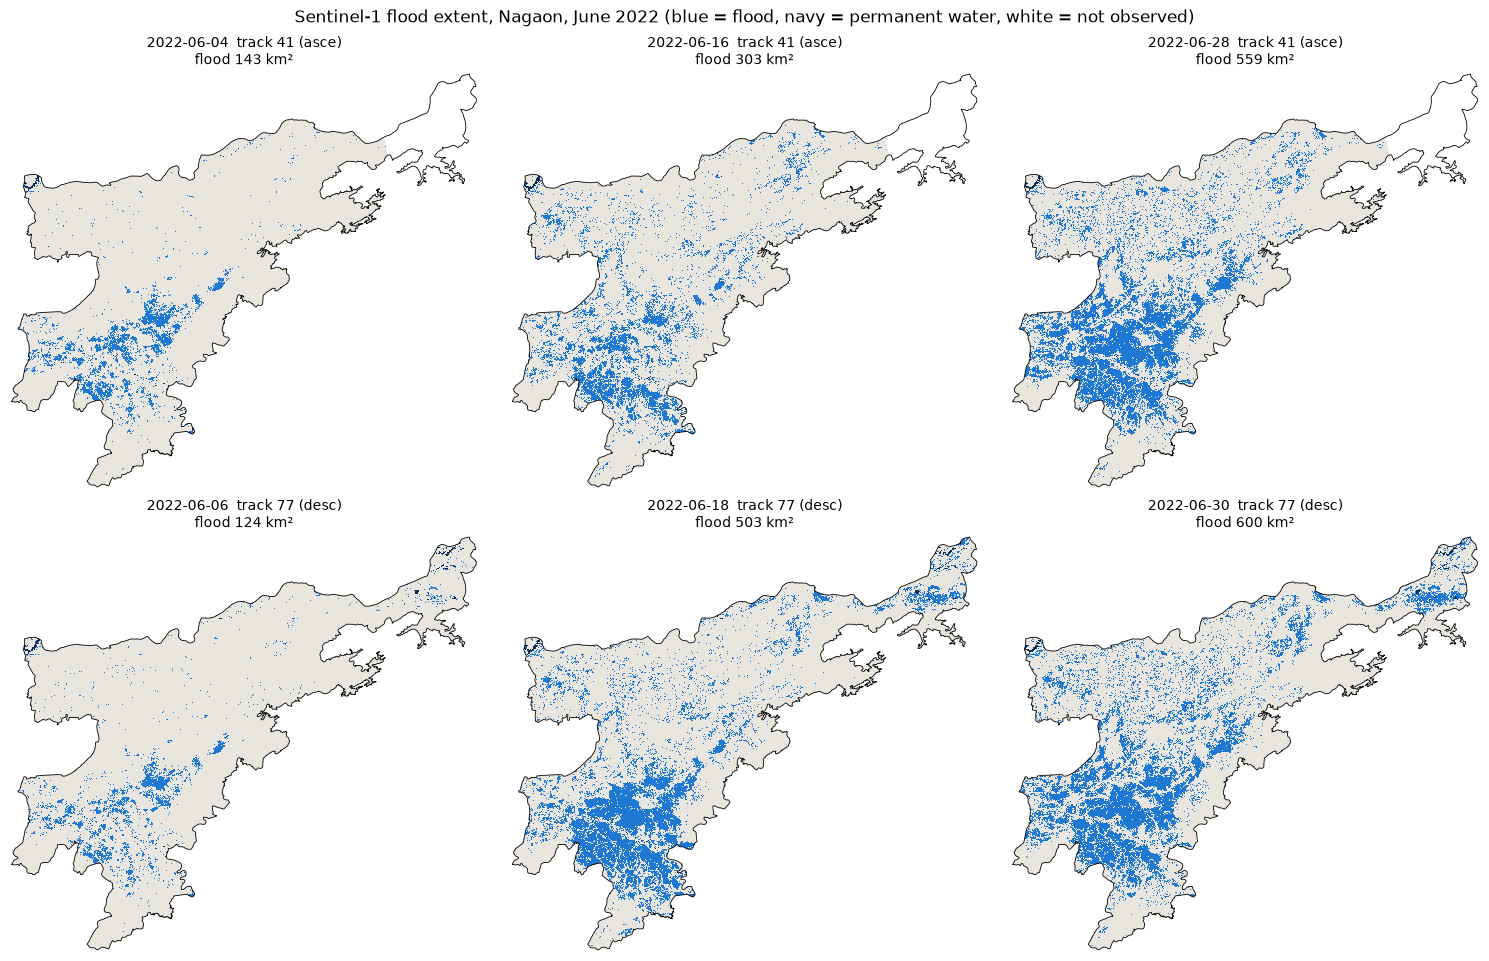

In [4]:
cmap = ListedColormap(["#e9e6df", "#1f78d1", "#0b2e59", "#ffffff"])
norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 255.5], cmap.N)
district = gpd.read_file(config.BOUNDARY_FILE).to_crs(config.CRS_METRIC)
p = C.profile(); t = p["transform"]
extent = [t.c, t.c + t.a * p["width"], t.f + t.e * p["height"], t.f]

fig, axes = plt.subplots(2, 3, figsize=(15, 9.5), constrained_layout=True)
for ax, ((date, orb), cl), r in zip(axes.T.ravel(), maps.items(), rows):
    ax.imshow(cl[::4, ::4], cmap=cmap, norm=norm, extent=extent, interpolation="nearest")
    district.boundary.plot(ax=ax, color="k", lw=0.6)
    ax.set_title(f"{date}  track {orb} ({config.TRACKS[orb][:4].lower()})\nflood {r['flood_km2']:.0f} km²", fontsize=10)
    ax.set_axis_off()
fig.suptitle("Sentinel-1 flood extent, Nagaon, June 2022 (blue = flood, navy = permanent water, white = not observed)")
fig.savefig(config.OUT_FIGURES / "flood_maps_june2022.png", dpi=150)
plt.show()

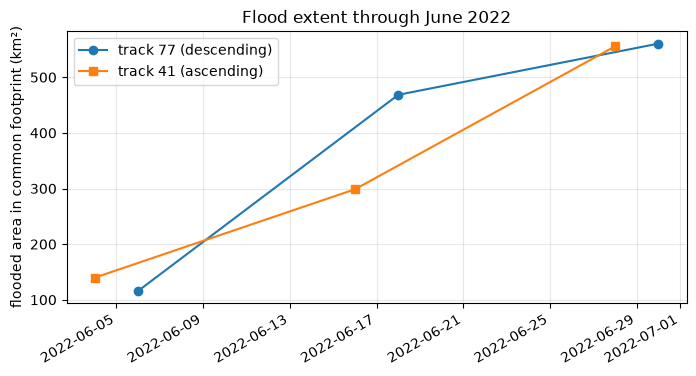

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
for orb, mk in [(77, "o"), (41, "s")]:
    d = areas[areas.track == orb]
    ax.plot(pd.to_datetime(d.date), d.flood_common_km2, mk + "-", label=f"track {orb} ({config.TRACKS[orb].lower()})")
ax.set_ylabel("flooded area in common footprint (km²)"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("Flood extent through June 2022")
fig.autofmt_xdate(); fig.savefig(config.OUT_FIGURES / "flood_area_timeseries.png", dpi=150, bbox_inches="tight")
plt.show()

## Quick check against independent reference maps

Full validation is in notebook 06; this is a sanity check. Metrics are computed on pixels inside the district observed on our date, treating permanent water as not flooded.

In [6]:
REF = config.DATA_PROCESSED / "reference_nagaon.gpkg"
pairs = [("mbrsc_s1_20220616", ("2022-06-16", 41)),
         ("eosrs_alos2_20220622", ("2022-06-18", 77)),
         ("eosrs_alos2_20220622", ("2022-06-28", 41))]
out = []
for layer, key in pairs:
    ref = C.rasterize_gdf(gpd.read_file(REF, layer=layer)).astype(bool)
    cl = maps[key]; ok = cl != 255
    ours = (cl == 1) & ok; refm = ref & ok
    tp = np.count_nonzero(ours & refm); fp = np.count_nonzero(ours & ~refm); fn = np.count_nonzero(~ours & refm)
    out.append({"reference": layer, "our_date": key[0], "track": key[1],
                "ref_km2": refm.sum() * C.PIX_KM2, "ours_km2": ours.sum() * C.PIX_KM2,
                "precision": tp / (tp + fp), "recall": tp / (tp + fn),
                "f1": 2 * tp / (2 * tp + fp + fn), "iou": tp / (tp + fp + fn)})
check = pd.DataFrame(out).round(3)
check.to_csv(config.OUT_TABLES / "reference_quickcheck.csv", index=False)
check

,reference,our_date,track,ref_km2,ours_km2,precision,recall,f1,iou
0,mbrsc_s1_20220616,2022-06-16,41,128.096,303.131,0.330,0.781,0.464,0.302
1,eosrs_alos2_20220622,2022-06-18,77,143.676,503.388,0.144,0.505,0.224,0.126
2,eosrs_alos2_20220622,2022-06-28,41,135.041,559.049,0.122,0.504,0.196,0.109
